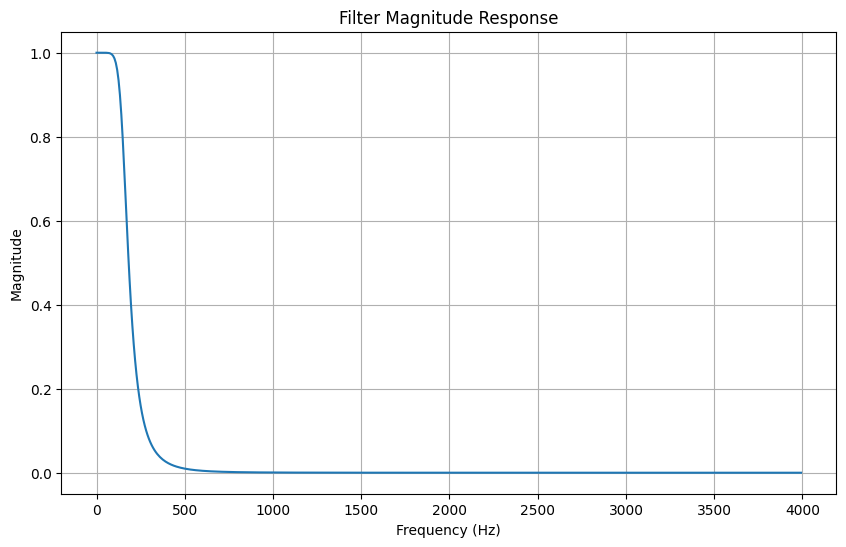

c:\Users\princ\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\princ\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


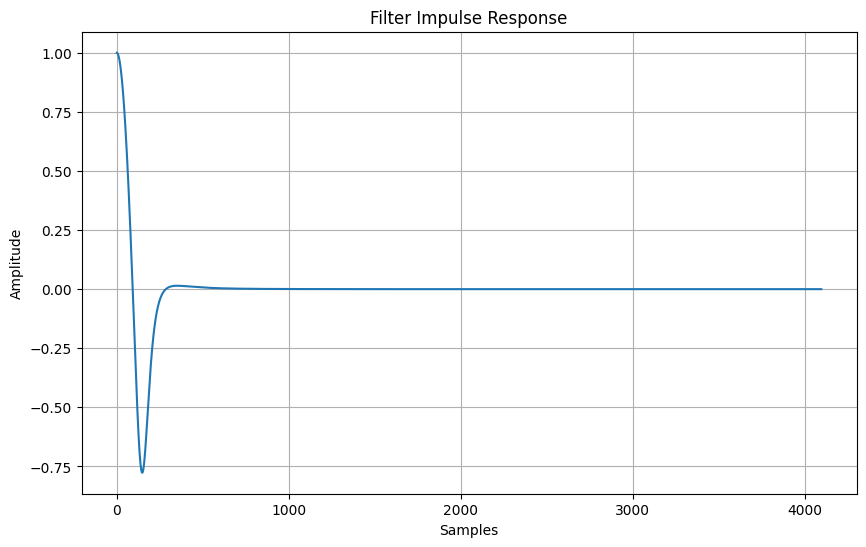

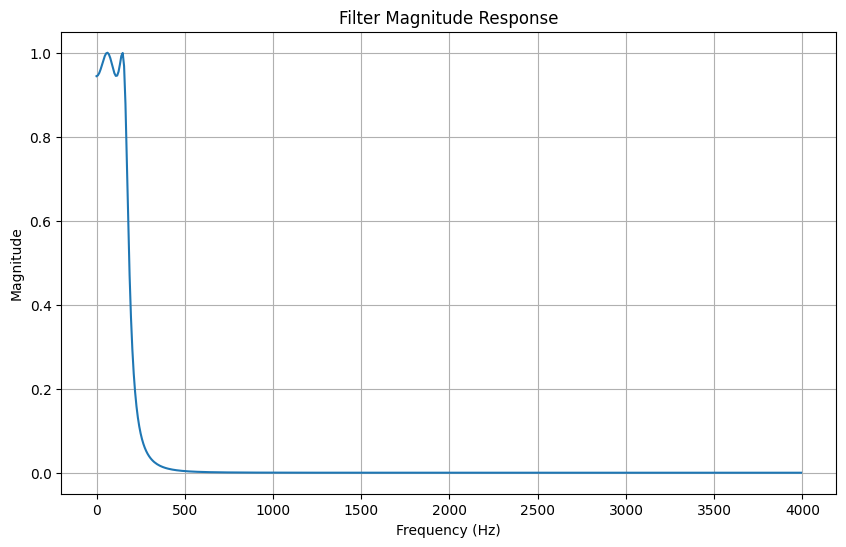

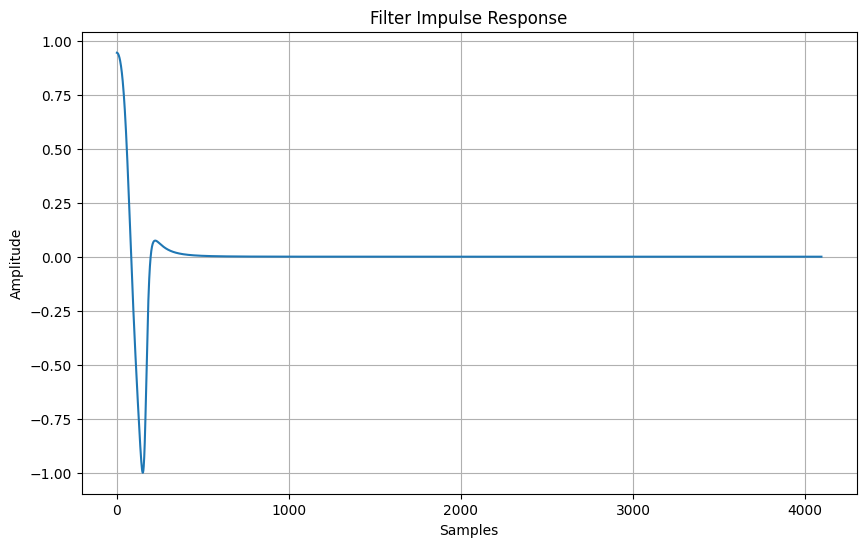

Filter coefficients saved at: filter_coefficients.txt


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, bilinear, freqz, cheby1

def design_butterworth_filter(filter_order, cutoff_frequency, sampling_frequency):
    # Design the analog Butterworth filter
    analog_b, analog_a = butter(filter_order, cutoff_frequency, analog=True, btype='low')

    # Perform the bilinear transformation
    digital_b, digital_a = bilinear(analog_b, analog_a, sampling_frequency)
    return digital_b, digital_a

def design_chebyshev_filter(filter_order, cutoff_frequency, sampling_frequency, ripple):
    # Design the analog Chebyshev filter
    analog_b, analog_a = cheby1(filter_order, ripple, cutoff_frequency, analog=True, btype='low')

    # Perform the bilinear transformation
    digital_b, digital_a = bilinear(analog_b, analog_a, sampling_frequency)
    return digital_b, digital_a

def plot_filter_response(digital_b, digital_a, sampling_frequency):
    # Compute the frequency response of the filter
    frequency, magnitude_response = freqz(digital_b, digital_a, fs=sampling_frequency)

    # Plot the magnitude response
    plt.figure(figsize=(10, 6))
    plt.plot(frequency, np.abs(magnitude_response))
    plt.title('Filter Magnitude Response')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude')
    plt.grid(True)
    plt.show()

    # Compute the impulse response of the filter
    _, impulse_response = freqz(digital_b, digital_a, fs=sampling_frequency, worN=4096)

    # Plot the impulse response
    plt.figure(figsize=(10, 6))
    plt.plot(impulse_response)
    plt.title('Filter Impulse Response')
    plt.xlabel('Samples')
    plt.ylabel('Amplitude')
    plt.grid(True)
    plt.show()

# Specify the desired filter specifications
filter_order = 4 # Filter order
cutoff_frequency = 1000 # Cutoff frequency in Hz
sampling_frequency = 8000 # Sampling frequency in Hz
ripple = 0.5 # Ripple factor for Chebyshev filter

# Design the Butterworth filter
digital_b, digital_a = design_butterworth_filter(filter_order, cutoff_frequency, sampling_frequency)
# Plot the Butterworth filter&#39;s magnitude response and impulse response
plot_filter_response(digital_b, digital_a, sampling_frequency)

# Design the Chebyshev filter
digital_b, digital_a = design_chebyshev_filter(filter_order, cutoff_frequency, sampling_frequency, ripple)

# Plot the Chebyshev filter&#39;s magnitude response and impulse response
plot_filter_response(digital_b, digital_a, sampling_frequency)

# Save the filter coefficients (optional)
filter_path = 'filter_coefficients.txt'
np.savetxt(filter_path, np.vstack((digital_b, digital_a)), delimiter=',')
print(f"Filter coefficients saved at: {filter_path}")

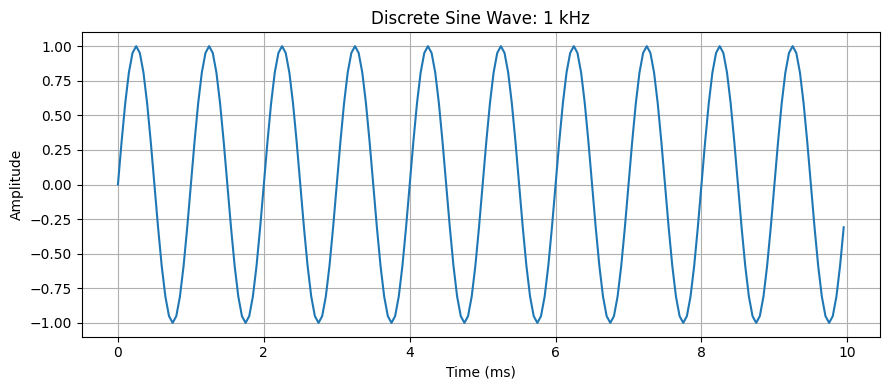

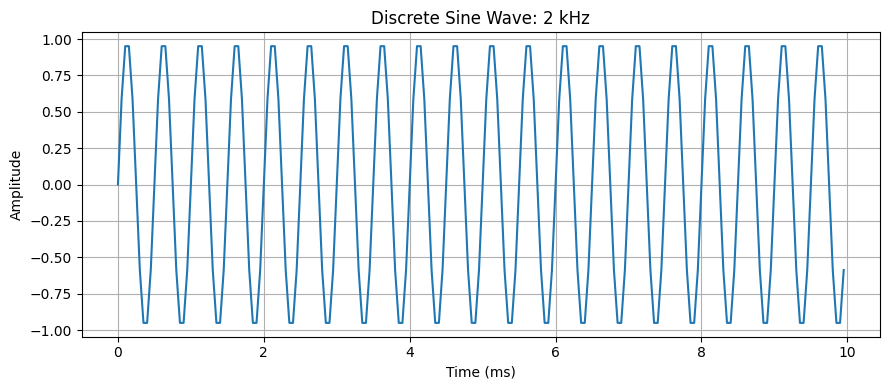

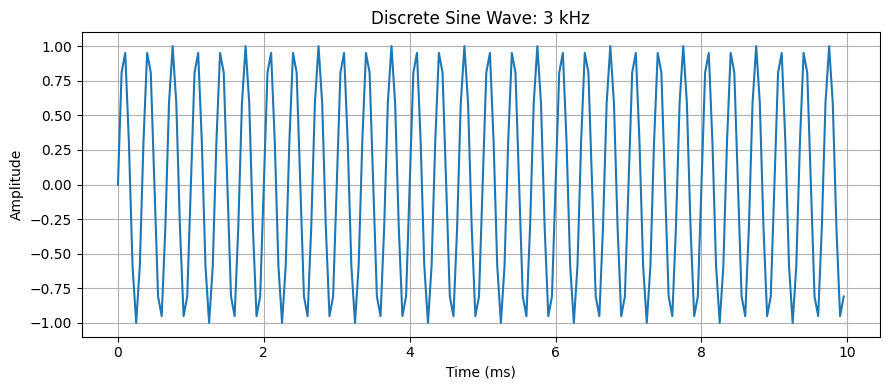

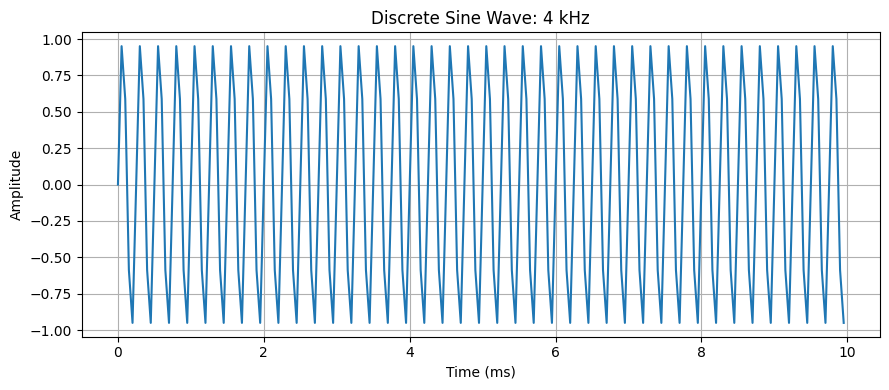

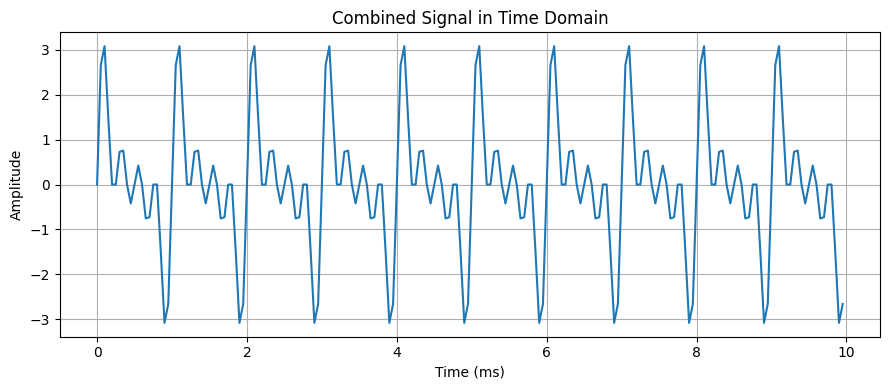

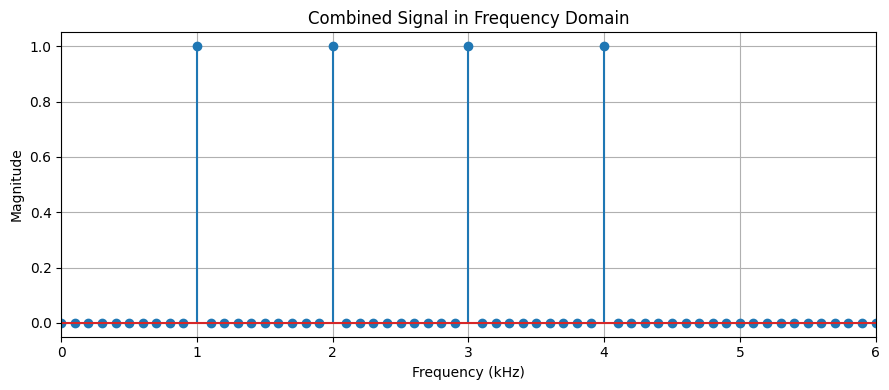

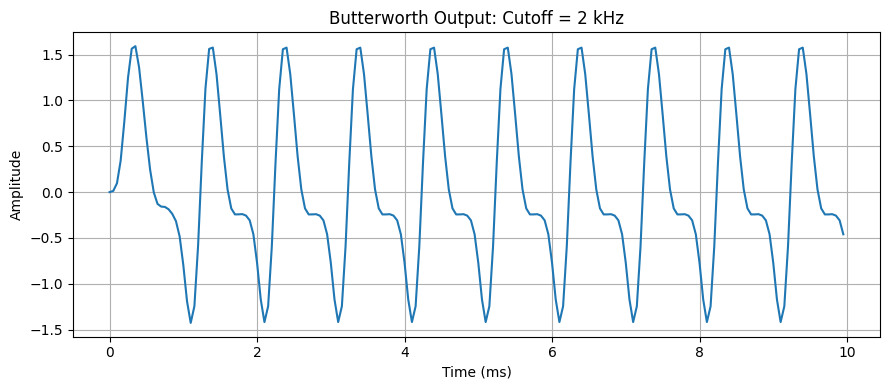

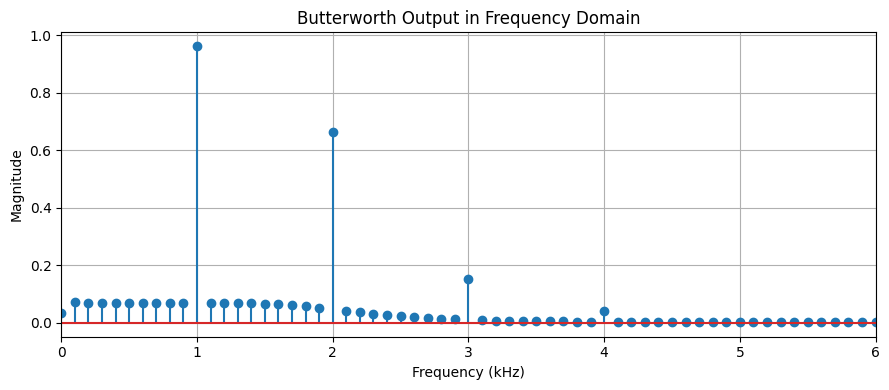

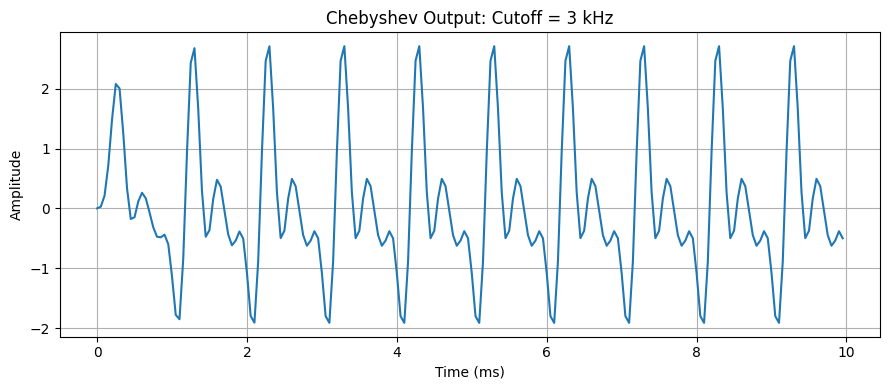

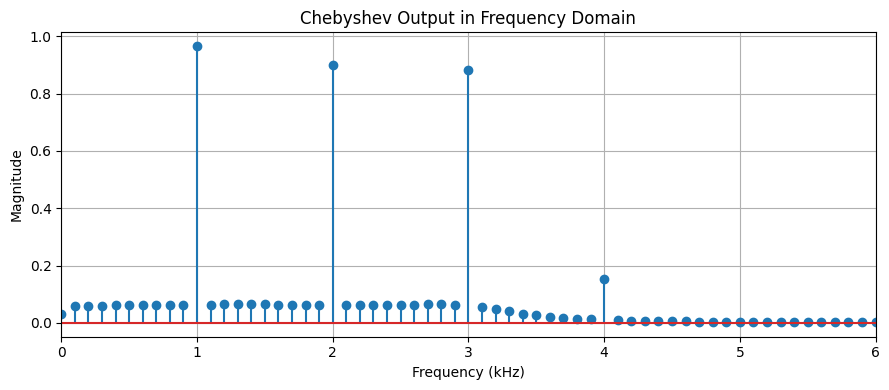

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, cheby1, sosfilt

# Sampling parameters
fs = 20000
duration = 0.01
t = np.arange(0, duration, 1/fs)

# Generate four discrete sine waves
x1 = np.sin(2 * np.pi * 1000 * t)
x2 = np.sin(2 * np.pi * 2000 * t)
x3 = np.sin(2 * np.pi * 3000 * t)
x4 = np.sin(2 * np.pi * 4000 * t)

# Plot individual sine waves
signals = [x1, x2, x3, x4]
frequencies = [1000, 2000, 3000, 4000]

for signal, freq in zip(signals, frequencies):
    plt.figure(figsize=(9, 4))
    plt.plot(t * 1000, signal)
    plt.title(f"Discrete Sine Wave: {freq/1000:.0f} kHz")
    plt.xlabel("Time (ms)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Add all four signals
x = x1 + x2 + x3 + x4

# Function to plot a signal in time domain
def plot_time(signal, title):
    plt.figure(figsize=(9, 4))
    plt.plot(t * 1000, signal)
    plt.title(title)
    plt.xlabel("Time (ms)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Function to plot a signal in frequency domain
def plot_frequency(signal, title):
    N = len(signal)
    freq = np.fft.rfftfreq(N, d=1/fs)
    spectrum = np.abs(np.fft.rfft(signal)) * 2 / N

    # Correct DC and Nyquist scaling if present
    spectrum[0] /= 2
    if N % 2 == 0:
        spectrum[-1] /= 2

    plt.figure(figsize=(9, 4))
    plt.stem(freq / 1000, spectrum)
    plt.title(title)
    plt.xlabel("Frequency (kHz)")
    plt.ylabel("Magnitude")
    plt.xlim(0, 6)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Plot combined signal
plot_time(x, "Combined Signal in Time Domain")
plot_frequency(x, "Combined Signal in Frequency Domain")

# Design Butterworth low-pass digital filter
# Cutoff frequency = 2 kHz
sos_butter = butter(
    4, 2000, btype='lowpass',
    fs=fs, output='sos'
)

# Filter combined signal
y_butter = sosfilt(sos_butter, x)

# Plot Butterworth output
plot_time(y_butter, "Butterworth Output: Cutoff = 2 kHz")
plot_frequency(y_butter, "Butterworth Output in Frequency Domain")

# Design Chebyshev Type-I low-pass digital filter
# Cutoff frequency = 3 kHz
sos_cheby = cheby1(
    4, 0.5, 3000, btype='lowpass',
    fs=fs, output='sos'
)

# Filter combined signal
y_cheby = sosfilt(sos_cheby, x)

# Plot Chebyshev output
plot_time(y_cheby, "Chebyshev Output: Cutoff = 3 kHz")
plot_frequency(y_cheby, "Chebyshev Output in Frequency Domain")